# GeoPulse – Synthetic GPS Data Generator

## Project Overview
This notebook demonstrates the generation of synthetic GPS mobility data
using the reusable GeoPulse GPS Generator module.

## Objectives
- Generate configurable GPS mobility records.
- Assign records to multiple devices.
- Generate timestamps within a specified period.
- Validate generated GPS data.
- Explore generated mobility data through EDA.

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Project configuration
PROJECT_ROOT = Path.cwd()
SRC_PATH = PROJECT_ROOT / "src"

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

# GeoPulse modules
from geopulse.gps_generator import generate_gps_data, save_gps_data
from geopulse.validation import validate_gps_data

print("GeoPulse GPS Generator Notebook")
print("Project Root:", PROJECT_ROOT)
print("Python Version:", sys.version)
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)

GeoPulse GPS Generator Notebook
Project Root: C:\Users\visha\OneDrive\Desktop\GeoPulse--Hyper-Local-Retail-Mobility-Analytics
Python Version: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
Pandas Version: 3.0.3
NumPy Version: 2.4.6


## 1. GPS Data Generation Configuration

Define the number of GPS records, devices, random seed, date range, and geographic boundaries for synthetic mobility data generation.

In [2]:
# GPS generation parameters

NUM_RECORDS = 1000
NUM_DEVICES = 100
RANDOM_SEED = 42

START_TIME = "2026-11-01"
END_TIME = "2026-11-05"

# Delhi NCR geographic boundaries
LAT_BOUNDS = (28.40, 28.90)
LONG_BOUNDS = (76.80, 77.40)

print("GPS Generation Configuration")
print("-" * 40)
print("Total Records:", NUM_RECORDS)
print("Total Devices:", NUM_DEVICES)
print("Random Seed:", RANDOM_SEED)
print("Start Time:", START_TIME)
print("End Time:", END_TIME)
print("Latitude Bounds:", LAT_BOUNDS)
print("Longitude Bounds:", LONG_BOUNDS)

GPS Generation Configuration
----------------------------------------
Total Records: 1000
Total Devices: 100
Random Seed: 42
Start Time: 2026-11-01
End Time: 2026-11-05
Latitude Bounds: (28.4, 28.9)
Longitude Bounds: (76.8, 77.4)


In [3]:
# Generate synthetic GPS data

gps_data = generate_gps_data(
    num_records=NUM_RECORDS,
    num_devices=NUM_DEVICES,
    start_time=START_TIME,
    end_time=END_TIME,
    seed=RANDOM_SEED,
    lat_bounds=LAT_BOUNDS,
    long_bounds=LONG_BOUNDS
)

print("GPS Dataset Generated Successfully!")
print("-" * 40)
print("Dataset Shape:", gps_data.shape)
print("Total GPS Records:", len(gps_data))
print("Unique Devices:", gps_data["DeviceID"].nunique())

display(gps_data.head(10))

GPS Dataset Generated Successfully!
----------------------------------------
Dataset Shape: (1000, 4)
Total GPS Records: 1000
Unique Devices: 100


,DeviceID,Lat,Long,Timestamp
0,D088,28.735927,76.820327,2026-11-04 02:17:59.210380940
1,D007,28.880293,77.209809,2026-11-02 18:07:56.388778309
2,D040,28.585456,77.370298,2026-11-04 10:25:31.441121373
3,D046,28.612541,77.297490,2026-11-03 18:56:50.390842916
4,D080,28.806061,76.966319,2026-11-01 09:02:27.691429971
5,D013,28.652881,76.831995,2026-11-04 21:39:35.084725662
6,D044,28.768287,77.364211,2026-11-04 01:04:09.881007866
7,D016,28.629855,77.362238,2026-11-04 03:27:43.823903715
8,D079,28.507748,77.119449,2026-11-01 12:17:56.071452668
9,D064,28.772602,77.185390,2026-11-02 19:14:13.380136708


In [4]:
# Validate generated GPS data

validation_result = validate_gps_data(gps_data)

print("GPS Data Validation Result:")
print("-" * 40)
print(validation_result)

GPS Data Validation Result:
----------------------------------------
{'missing_columns': [], 'missing_values': {'DeviceID': 0, 'Lat': 0, 'Long': 0, 'Timestamp': 0}, 'duplicate_rows': 0, 'non_numeric_latitudes': 0, 'invalid_latitudes': 0, 'non_numeric_longitudes': 0, 'invalid_longitudes': 0, 'invalid_timestamps': 0, 'empty_device_ids': 0}


In [5]:
# Basic dataset information

print("GPS Dataset Overview")
print("=" * 50)

print("\n1. Dataset Information")
print("Total Rows:", gps_data.shape[0])
print("Total Columns:", gps_data.shape[1])
print("Column Names:", gps_data.columns.tolist())

print("\n2. Statistical Summary")
display(gps_data[["Lat", "Long"]].describe())

print("\n3. Device Analysis")
print("Unique Devices:", gps_data["DeviceID"].nunique())
print("Average Records per Device:",
      round(len(gps_data) / gps_data["DeviceID"].nunique(), 2))

print("\n4. Timestamp Analysis")
print("First Timestamp:", gps_data["Timestamp"].min())
print("Last Timestamp:", gps_data["Timestamp"].max())
print("Total Duration:",
      gps_data["Timestamp"].max() - gps_data["Timestamp"].min())

print("\n5. Data Types")
display(gps_data.dtypes.to_frame(name="Data Type"))

GPS Dataset Overview

1. Dataset Information
Total Rows: 1000
Total Columns: 4
Column Names: ['DeviceID', 'Lat', 'Long', 'Timestamp']

2. Statistical Summary


,Lat,Long
count,1000.000000,1000.000000
mean,28.649453,77.097805
std,0.144419,0.175056
min,28.400284,76.800495
25%,28.524949,76.946754
50%,28.646330,77.103510
75%,28.778050,77.247474
max,28.899883,77.399645



3. Device Analysis
Unique Devices: 100
Average Records per Device: 10.0

4. Timestamp Analysis
First Timestamp: 2026-11-01 00:07:06.146404115
Last Timestamp: 2026-11-04 23:54:50.594851896
Total Duration: 3 days 23:47:44.448447781

5. Data Types


,Data Type
DeviceID,str
Lat,float64
Long,float64
Timestamp,datetime64[ns]


Device-wise GPS Record Distribution
--------------------------------------------------
Total Devices: 100
Minimum Records: 2
Maximum Records: 21
Average Records: 10.0


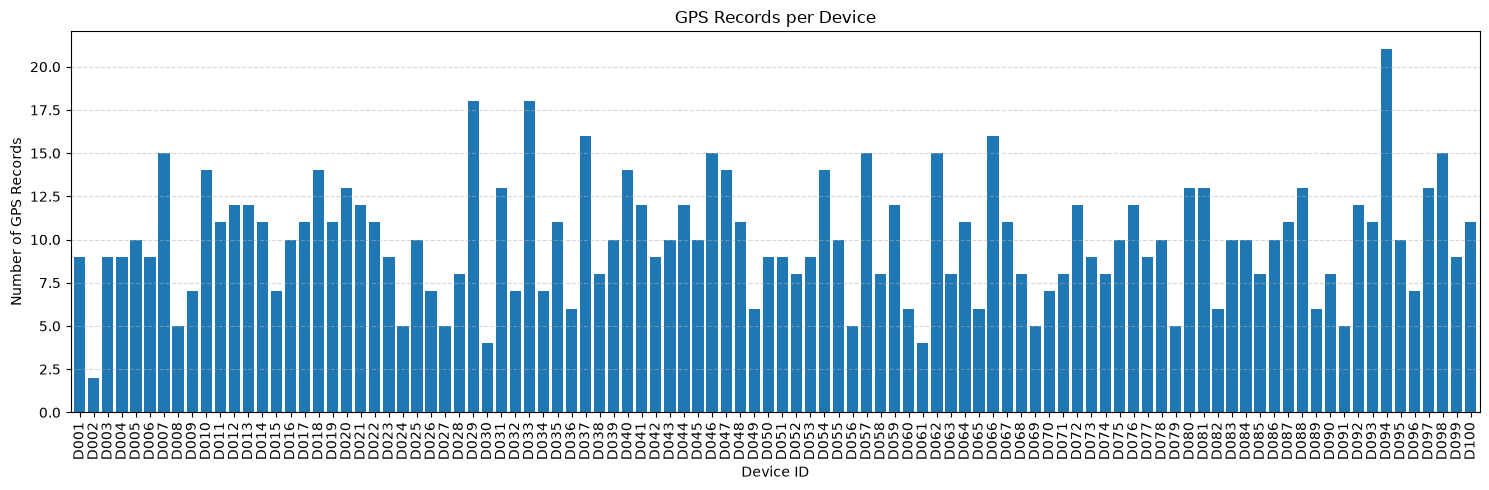

In [6]:
# Count GPS records for each device

device_counts = gps_data["DeviceID"].value_counts().sort_index()

print("Device-wise GPS Record Distribution")
print("-" * 50)
print("Total Devices:", len(device_counts))
print("Minimum Records:", device_counts.min())
print("Maximum Records:", device_counts.max())
print("Average Records:", round(device_counts.mean(), 2))

plt.figure(figsize=(15, 5))

device_counts.plot(kind="bar", width=0.8)

plt.title("GPS Records per Device")
plt.xlabel("Device ID")
plt.ylabel("Number of GPS Records")
plt.xticks(rotation=90)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

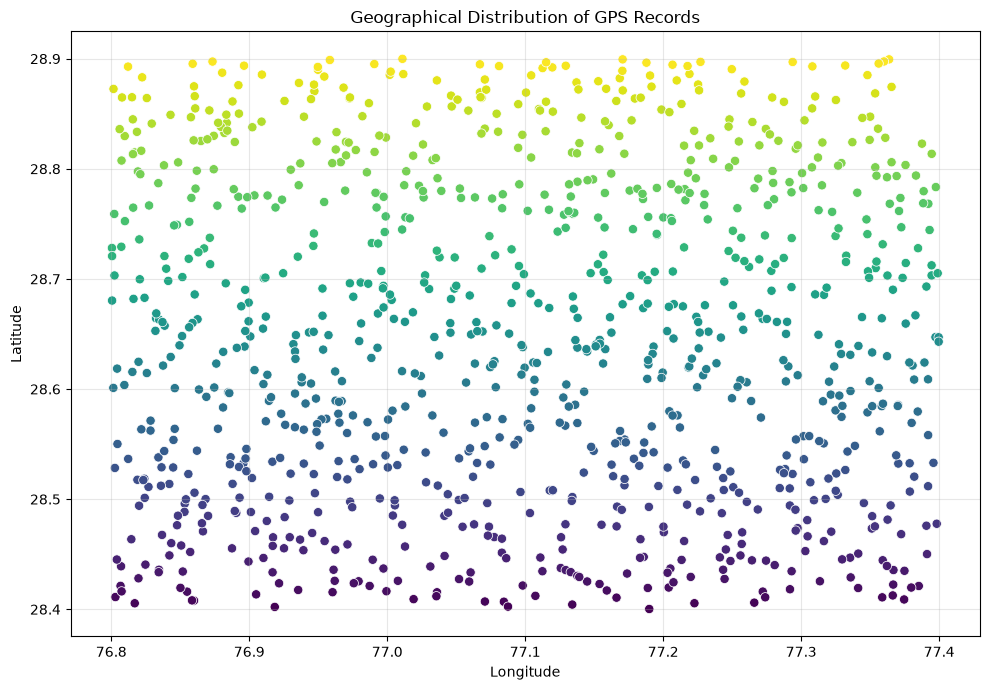

In [7]:
# Visualize GPS coordinates

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=gps_data,
    x="Long",
    y="Lat",
    hue="Lat",
    palette="viridis",
    s=45,
    legend=False
)

plt.title("Geographical Distribution of GPS Records")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Daily GPS Record Distribution
----------------------------------------


,GPS Records
Date,
2026-11-01,263
2026-11-02,240
2026-11-03,240
2026-11-04,257


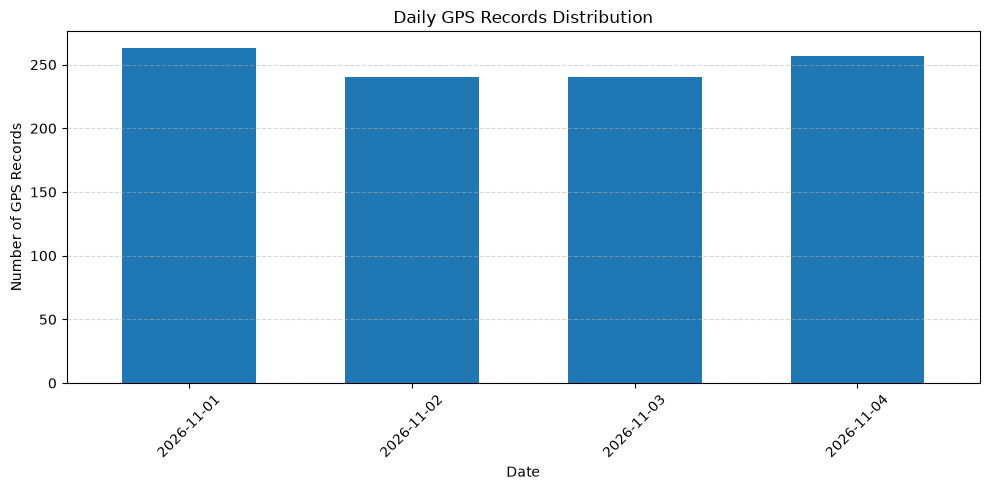

In [8]:
# Extract date from timestamp

gps_data["Date"] = gps_data["Timestamp"].dt.date

daily_records = gps_data.groupby("Date").size()

print("Daily GPS Record Distribution")
print("-" * 40)
display(daily_records.to_frame(name="GPS Records"))

plt.figure(figsize=(10, 5))

daily_records.plot(kind="bar", width=0.6)

plt.title("Daily GPS Records Distribution")
plt.xlabel("Date")
plt.ylabel("Number of GPS Records")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Hourly GPS Activity
----------------------------------------


,GPS Records
Hour,
0,37
1,39
2,48
3,42
4,50
5,39
6,41
7,27
8,47


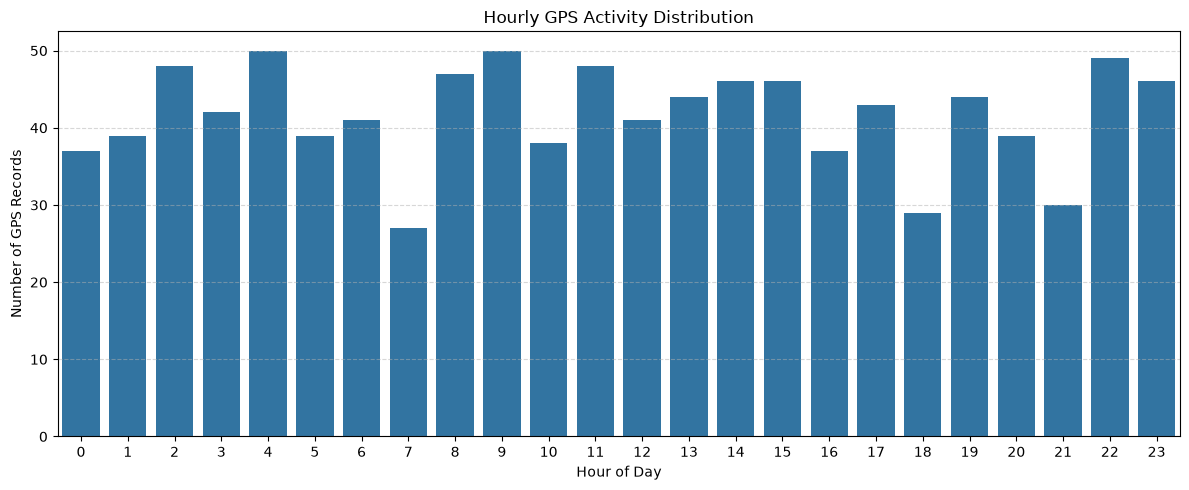

In [9]:
# Extract hour from timestamp

gps_data["Hour"] = gps_data["Timestamp"].dt.hour

hourly_records = gps_data.groupby("Hour").size()

print("Hourly GPS Activity")
print("-" * 40)
display(hourly_records.to_frame(name="GPS Records"))

plt.figure(figsize=(12, 5))

sns.barplot(
    x=hourly_records.index,
    y=hourly_records.values
)

plt.title("Hourly GPS Activity Distribution")
plt.xlabel("Hour of Day")
plt.ylabel("Number of GPS Records")
plt.xticks(range(24))
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 2. Export Generated GPS Dataset

Save the generated synthetic GPS mobility records into a separate CSV file for future analysis and spatial processing.

In [10]:
# Save generated GPS dataset safely

OUTPUT_PATH = PROJECT_ROOT / "data" / "geopulse_gps_generated.csv"

# Keep only the original four GPS columns
gps_export = gps_data[
    ["DeviceID", "Lat", "Long", "Timestamp"]
].copy()

if OUTPUT_PATH.exists():
    print("File already exists. No changes made.")
    print("Existing File:", OUTPUT_PATH)
else:
    saved_path = save_gps_data(
        gps_export,
        OUTPUT_PATH
    )

    print("GPS Dataset Saved Successfully!")
    print("File Location:", saved_path)
    print("Records Saved:", len(gps_export))
    print("Dataset Shape:", gps_export.shape)

GPS Dataset Saved Successfully!
File Location: C:\Users\visha\OneDrive\Desktop\GeoPulse--Hyper-Local-Retail-Mobility-Analytics\data\geopulse_gps_generated.csv
Records Saved: 1000
Dataset Shape: (1000, 4)


In [11]:
# Read saved CSV file

verified_gps_data = pd.read_csv(OUTPUT_PATH)

# Convert Timestamp back to datetime
verified_gps_data["Timestamp"] = pd.to_datetime(
    verified_gps_data["Timestamp"]
)

print("GPS Dataset Export Verification")
print("=" * 45)

print("File Exists:", OUTPUT_PATH.exists())
print("Dataset Shape:", verified_gps_data.shape)
print("Total Records:", len(verified_gps_data))
print("Unique Devices:", verified_gps_data["DeviceID"].nunique())

print("\nColumn Names:")
print(verified_gps_data.columns.tolist())

print("\nMissing Values:")
display(verified_gps_data.isnull().sum().to_frame("Missing Values"))

print("\nDataset Preview:")
display(verified_gps_data.head())

GPS Dataset Export Verification
File Exists: True
Dataset Shape: (1000, 4)
Total Records: 1000
Unique Devices: 100

Column Names:
['DeviceID', 'Lat', 'Long', 'Timestamp']

Missing Values:


,Missing Values
DeviceID,0
Lat,0
Long,0
Timestamp,0



Dataset Preview:


,DeviceID,Lat,Long,Timestamp
0,D088,28.735927,76.820327,2026-11-04 02:17:59.210380940
1,D007,28.880293,77.209809,2026-11-02 18:07:56.388778309
2,D040,28.585456,77.370298,2026-11-04 10:25:31.441121373
3,D046,28.612541,77.297490,2026-11-03 18:56:50.390842916
4,D080,28.806061,76.966319,2026-11-01 09:02:27.691429971
